In [1]:
import torch #for tensor
import torch.nn as nn #module for nn creation
from torch.utils.data import DataLoader #to transfer data in nn by batches
from torchvision import datasets #load existing datasets
from torchvision.transforms import ToTensor #transform photo in tensor
import time
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

if torch.cuda.is_available(): #try to acess GPU cuda
    print(torch.cuda.get_device_name(0))
    device=torch.device('cuda')
else:
    print("Use CPU")

NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
#DATA testing different noise level
X,y=make_moons(n_samples=500,noise=0,random_state=0) #random state to get the same data
X1,y1=make_moons(n_samples=500,noise=0.1,random_state=0) #random state to get the same data
X2,y2=make_moons(n_samples=500,noise=0.2,random_state=0) #random state to get the same data
X3,y3=make_moons(n_samples=500,noise=0.3,random_state=0) #random state to get the same data
X4,y4=make_moons(n_samples=500,noise=0.4,random_state=0) #random state to get the same data
X5,y5=make_moons(n_samples=500,noise=0.5,random_state=0) #random state to get the same data
X8,y8=make_moons(n_samples=500,noise=0.8,random_state=0) #random state to get the same data
X9,y9=make_moons(n_samples=500,noise=0.9,random_state=0) #random state to get the same data
print(f"X:{X2.shape}") #2 features
print(f"y:{y2.shape}")

X:(500, 2)
y:(500,)


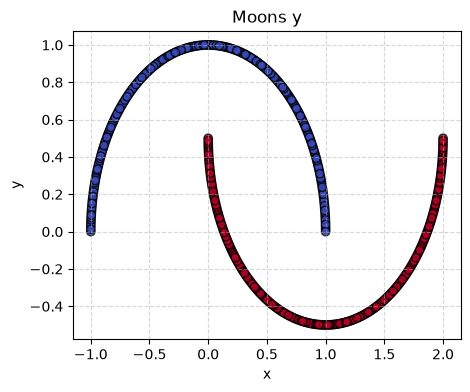

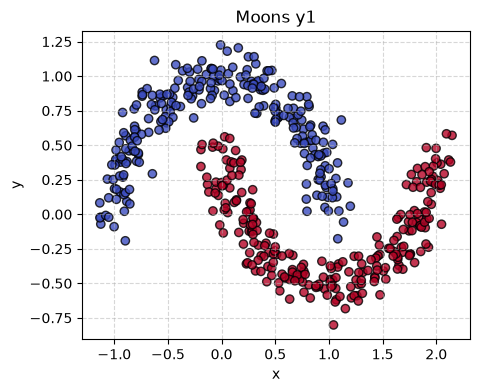

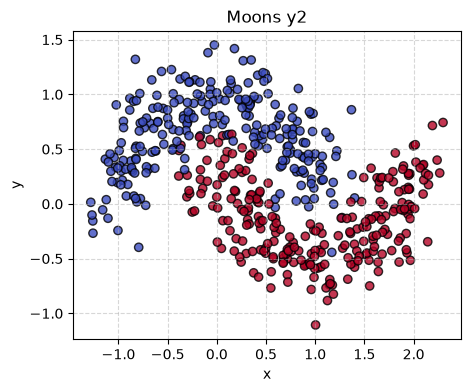

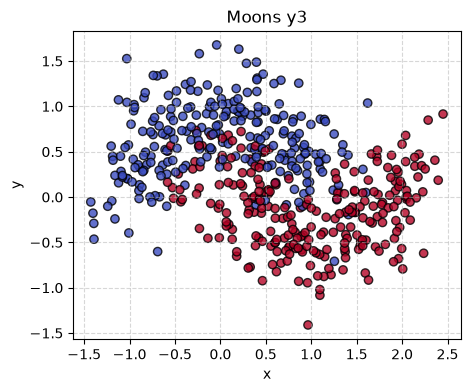

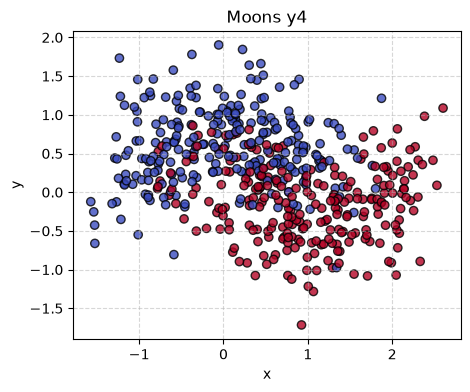

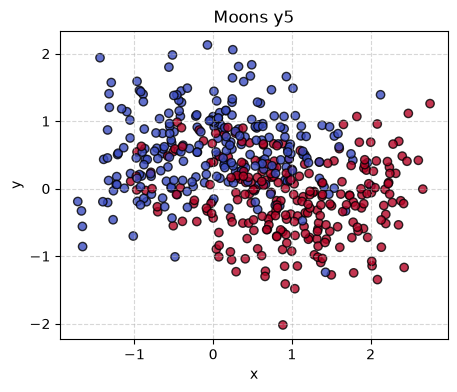

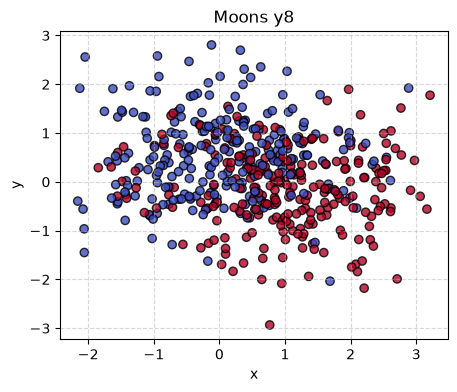

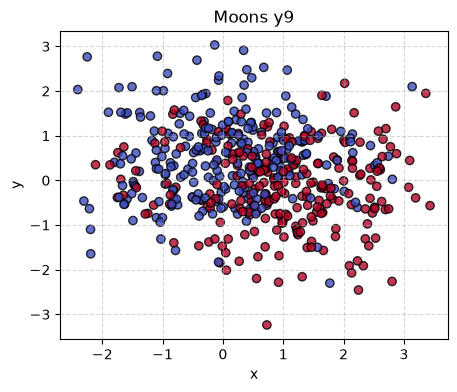

In [3]:
plt.figure(figsize=(5,4)) #area
plt.scatter(X[:,0],X[:,1],c=y,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X1[:,0],X1[:,1],c=y1,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y1")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X2[:,0],X2[:,1],c=y2,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y2")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X3[:,0],X3[:,1],c=y3,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y3")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X4[:,0],X4[:,1],c=y4,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y4")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X5[:,0],X5[:,1],c=y5,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y5")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X8[:,0],X8[:,1],c=y8,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y8")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

plt.figure(figsize=(5,4)) #area
plt.scatter(X9[:,0],X9[:,1],c=y9,cmap='coolwarm',edgecolors='k',alpha=0.8) #assigns different colors by point's class
#all rows-x,all rows-y,c-assigns colors,colormap,k-black,alpha-transparency
plt.title("Moons y9")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

In [4]:
X=torch.tensor(X,dtype=torch.float)
y=torch.tensor(y,dtype=torch.float)

X1=torch.tensor(X1,dtype=torch.float)
y1=torch.tensor(y1,dtype=torch.float)

X2=torch.tensor(X2,dtype=torch.float)
y2=torch.tensor(y2,dtype=torch.float)

X3=torch.tensor(X3,dtype=torch.float)
y3=torch.tensor(y3,dtype=torch.float)

X4=torch.tensor(X4,dtype=torch.float)
y4=torch.tensor(y4,dtype=torch.float)

X5=torch.tensor(X5,dtype=torch.float)
y5=torch.tensor(y5,dtype=torch.float)

X8=torch.tensor(X8,dtype=torch.float)
y8=torch.tensor(y8,dtype=torch.float)

X9=torch.tensor(X9,dtype=torch.float)
y9=torch.tensor(y9,dtype=torch.float)

In [5]:
#Train
def train(model,criterion,optimizer,X,y,epochs=50,log_gradients=False): #False speed up training,True if have problems vanishing,dying and need diagnostic
    start=time.time()
    X=X.to(device)
    y=y.to(device)

    for epoch in range(epochs):
        optimizer.zero_grad()
        out=model(X)
        loss=criterion(out,y.unsqueeze(1)) #transform tesnor [500] to [500,1] to match nn model outputs
        loss.backward()
        optimizer.step()

        if (epoch%10==0):
            print(f"Epoch:{epoch},loss={loss.item()}") #item to extract number not a tensor's object

    end=time.time()
    finish=end-start
    print(f"Training time={finish} seconds")

def test(model,criterion,X,y,log_gradient=False):
    with torch.no_grad():
        X=X.to(device)
        y=y.to(device)

        output=model(X)
        predictions=(output>=0.5).float() #<0.5=0 >0.5=1 
        correct=(predictions==y.unsqueeze(1)).sum().item() #transform tesnor [500] to [500,1] to match nn model outputs
        total=y.size(0) #500
        accuracy=(correct/total)*100
        print(f"Accuracy={correct}/{total}({accuracy:.2f}%)")
        
        
    

In [6]:
model=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model=model.to(device)
opt=torch.optim.Adam(model.parameters(),lr=0.1)

model1=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model1=model1.to(device)
opt1=torch.optim.Adam(model1.parameters(),lr=0.1)

model2=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model2=model2.to(device)
opt2=torch.optim.Adam(model2.parameters(),lr=0.1)

model3=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model3=model3.to(device)
opt3=torch.optim.Adam(model3.parameters(),lr=0.1)

model4=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model4=model4.to(device)
opt4=torch.optim.Adam(model4.parameters(),lr=0.1)

model5=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model5=model5.to(device)
opt5=torch.optim.Adam(model5.parameters(),lr=0.1)

model8=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model8=model8.to(device)
opt8=torch.optim.Adam(model8.parameters(),lr=0.1)

model9=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model9=model9.to(device)
opt9=torch.optim.Adam(model9.parameters(),lr=0.1)

loss=nn.BCELoss()
print(model)

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


In [7]:
print("Model 0")
train(model,loss,opt,X,y)

print("Model 1")
train(model1,loss,opt1,X1,y1)

print("Model 2")
train(model2,loss,opt2,X2,y2)

print("Model 3")
train(model3,loss,opt3,X3,y3)

print("Model 4")
train(model4,loss,opt4,X4,y4)

print("Model 5")
train(model5,loss,opt5,X5,y5)

print("Model 8")
train(model8,loss,opt8,X8,y8)

print("Model 9")
train(model9,loss,opt9,X9,y9)

Model 0
Epoch:0,loss=0.705481767654419
Epoch:10,loss=0.2156853973865509
Epoch:20,loss=0.0557451955974102
Epoch:30,loss=0.002698263619095087
Epoch:40,loss=0.00022770716168452054
Training time=0.4873504638671875 seconds
Model 1
Epoch:0,loss=0.6929729580879211
Epoch:10,loss=0.27206239104270935
Epoch:20,loss=0.20722533762454987
Epoch:30,loss=0.14161159098148346
Epoch:40,loss=0.030948437750339508
Training time=0.16229653358459473 seconds
Model 2
Epoch:0,loss=0.6940451860427856
Epoch:10,loss=0.2964039146900177
Epoch:20,loss=0.2601313591003418
Epoch:30,loss=0.23507682979106903
Epoch:40,loss=0.1820850968360901
Training time=0.16451263427734375 seconds
Model 3
Epoch:0,loss=0.7101835012435913
Epoch:10,loss=0.3609776794910431
Epoch:20,loss=0.30275416374206543
Epoch:30,loss=0.24078498780727386
Epoch:40,loss=0.22739437222480774
Training time=0.16042542457580566 seconds
Model 4
Epoch:0,loss=0.6860053539276123
Epoch:10,loss=0.3977198302745819
Epoch:20,loss=0.3800678253173828
Epoch:30,loss=0.362446844

In [8]:
#Generate new data to check accuracy
X,y=make_moons(n_samples=500,noise=0,random_state=1) #random state to get the same data
X1,y1=make_moons(n_samples=500,noise=0.1,random_state=1) #random state to get the same data
X2,y2=make_moons(n_samples=500,noise=0.2,random_state=1) #random state to get the same data
X3,y3=make_moons(n_samples=500,noise=0.3,random_state=1) #random state to get the same data
X4,y4=make_moons(n_samples=500,noise=0.4,random_state=1) #random state to get the same data
X5,y5=make_moons(n_samples=500,noise=0.5,random_state=1) #random state to get the same data
X8,y8=make_moons(n_samples=500,noise=0.8,random_state=1) #random state to get the same data
X9,y9=make_moons(n_samples=500,noise=0.9,random_state=1) #random state to get the same data

X=torch.tensor(X,dtype=torch.float)
y=torch.tensor(y,dtype=torch.float)

X1=torch.tensor(X1,dtype=torch.float)
y1=torch.tensor(y1,dtype=torch.float)

X2=torch.tensor(X2,dtype=torch.float)
y2=torch.tensor(y2,dtype=torch.float)

X3=torch.tensor(X3,dtype=torch.float)
y3=torch.tensor(y3,dtype=torch.float)

X4=torch.tensor(X4,dtype=torch.float)
y4=torch.tensor(y4,dtype=torch.float)

X5=torch.tensor(X5,dtype=torch.float)
y5=torch.tensor(y5,dtype=torch.float)

X8=torch.tensor(X8,dtype=torch.float)
y8=torch.tensor(y8,dtype=torch.float)

X9=torch.tensor(X9,dtype=torch.float)
y9=torch.tensor(y9,dtype=torch.float)

In [9]:
print("Model 0")
test(model,loss,X,y)

print("Model 1")
test(model1,loss,X1,y1)

print("Model 2")
test(model2,loss,X2,y2)

print("Model 3")
test(model3,loss,X3,y3)

print("Model 4")
test(model4,loss,X4,y4)

print("Model 5")
test(model5,loss,X5,y5)

print("Model 8")
test(model8,loss,X8,y8)

print("Model 9")
test(model9,loss,X9,y9)

Model 0
Accuracy=500/500(100.00%)
Model 1
Accuracy=500/500(100.00%)
Model 2
Accuracy=481/500(96.20%)
Model 3
Accuracy=453/500(90.60%)
Model 4
Accuracy=430/500(86.00%)
Model 5
Accuracy=414/500(82.80%)
Model 8
Accuracy=381/500(76.20%)
Model 9
Accuracy=367/500(73.40%)


In [10]:
#2 part
X2,y2=make_moons(n_samples=500,noise=0.2,random_state=0) #random state to get the same data
X2=torch.tensor(X2,dtype=torch.float)
y2=torch.tensor(y2,dtype=torch.float)

#1
model=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model=model.to(device)
opt=torch.optim.Adam(model.parameters(),lr=0.1)

for layer in model:
    if hasattr(layer,"weight"): #check are weights exist
        nn.init.zeros_(layer.weight)
        nn.init.zeros_(layer.bias)

train(model,loss,opt,X2,y2) #Loss did not change
test(model,loss,X2,y2)
print()
#2
model=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model=model.to(device)
opt=torch.optim.Adam(model.parameters(),lr=0.1)

for layer in model:
    if hasattr(layer,"weight"): #check are weights exist
        nn.init.zeros_(layer.weight)
        #only weighеs=0 all 8 neurons get the same signal and updated similar,so layer have only 1 neuron
        # 2-1-1-1

train(model,loss,opt,X2,y2) 
test(model,loss,X2,y2)
print()
#3
model=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model=model.to(device)
opt=torch.optim.Adam(model.parameters(),lr=0.1)

for layer in model:
    if hasattr(layer,"weight"): #check are weights exist
        nn.init.xavier_uniform_(layer.weight) #random weights with scale dependent on input and output magnitude

train(model,loss,opt,X2,y2)
test(model,loss,X2,y2)


Epoch:0,loss=0.6931472420692444
Epoch:10,loss=0.6932214498519897
Epoch:20,loss=0.6931501030921936
Epoch:30,loss=0.6931496858596802
Epoch:40,loss=0.6931540369987488
Training time=0.18637537956237793 seconds
Accuracy=250/500(50.00%)

Epoch:0,loss=0.7019680142402649
Epoch:10,loss=0.5121079087257385
Epoch:20,loss=0.3668184280395508
Epoch:30,loss=0.3371100425720215
Epoch:40,loss=0.311235249042511
Training time=0.18340158462524414 seconds
Accuracy=434/500(86.80%)

Epoch:0,loss=0.6842979788780212
Epoch:10,loss=0.35555407404899597
Epoch:20,loss=0.23516911268234253
Epoch:30,loss=0.13379544019699097
Epoch:40,loss=0.09557440876960754
Training time=0.17592597007751465 seconds
Accuracy=485/500(97.00%)


In [11]:
#3 High SMALL LR
X2,y2=make_moons(n_samples=500,noise=0.2,random_state=0) #random state to get the same data
X2=torch.tensor(X2,dtype=torch.float)
y2=torch.tensor(y2,dtype=torch.float)

model=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model=model.to(device)
opt=torch.optim.SGD(model.parameters(),lr=10) #Train stuck after 10 epochs
loss=nn.BCELoss()

train(model,loss,opt,X2,y2)
print()
test(model,loss,X2,y2)
print()

model=nn.Sequential( #2-8+R-8+R-1+S
    nn.Linear(2,8),nn.ReLU(),
    nn.Linear(8,8),nn.ReLU(),
    nn.Linear(8,1),nn.Sigmoid())
model=model.to(device)
opt=torch.optim.SGD(model.parameters(),lr=0.1)

train(model,loss,opt,X2,y2)
print()
test(model,loss,X2,y2)

Epoch:0,loss=0.7372300028800964
Epoch:10,loss=1.044419288635254
Epoch:20,loss=1.0444276332855225
Epoch:30,loss=1.0444276332855225
Epoch:40,loss=1.0444276332855225
Training time=0.15029525756835938 seconds

Accuracy=250/500(50.00%)

Epoch:0,loss=0.7092876434326172
Epoch:10,loss=0.6754347085952759
Epoch:20,loss=0.6414111852645874
Epoch:30,loss=0.6106379628181458
Epoch:40,loss=0.5793916583061218
Training time=0.14635109901428223 seconds

Accuracy=399/500(79.80%)


In [12]:
#4 Vanishin gradient
X2,y2=make_moons(n_samples=500,noise=0.2,random_state=0) #random state to get the same data
X2=torch.tensor(X2,dtype=torch.float)
y2=torch.tensor(y2,dtype=torch.float)


layersS=[]
in_dim=2

for _ in range(9):
    layersS.append(nn.Linear(in_dim,8))
    layersS.append(nn.Sigmoid())
    in_dim=8
layersS.append(nn.Linear(in_dim,1))
layersS.append(nn.Sigmoid())

modelS=nn.Sequential(*layersS) #2-8S-8S-8S-8S-8S-8S-8S-8S-1S


layersR=[]
in_dim=2

for _ in range(9):
    layersR.append(nn.Linear(in_dim,8))
    layersR.append(nn.ReLU())
    in_dim=8
layersR.append(nn.Linear(in_dim,1))
layersR.append(nn.Sigmoid())

modelR=nn.Sequential(*layersR) #2-8R-8R-8R-8R-8R-8R-8R-8R-1S


#New Train
def train(model,criterion,optimizer,X,y,epochs=50,log_gradients=False): #False speed up training,True if have problems vanishing,dying and need diagnostic
    start=time.time()
    model=model.to(device)
    X=X.to(device)
    y=y.to(device)

    for epoch in range(epochs):
        optimizer.zero_grad()
        out=model(X)
        loss=criterion(out,y.unsqueeze(1)) #transform tesnor [500] to [500,1] to match nn model outputs
        loss.backward()
        optimizer.step()

    if log_gradients and epoch==epochs-1:
        print("Gradient norm per layer")
        for i,layer in enumerate(model): #go through layers
            if hasattr(layer,"weight") and layer.weight.grad is not None:
                print(f"Layer{i}:{layer.weight.grad.norm().item():.10f}") #norm of gradient

    end=time.time()
    finish=end-start
    print(f"Training time={finish} seconds")

optS=torch.optim.Adam(modelS.parameters(),lr=0.01)
optR=torch.optim.Adam(modelR.parameters(),lr=0.01)
loss=nn.BCELoss()

train(modelS,loss,optS,X2,y2,log_gradients=True)
print()
train(modelR,loss,optR,X2,y2,log_gradients=True)

print()
print("S")
test(modelS,loss,X2,y2)
print()
print("R")
test(modelR,loss,X2,y2)

Gradient norm per layer
Layer0:0.0000000400
Layer2:0.0000000690
Layer4:0.0000000780
Layer6:0.0000001409
Layer8:0.0000009607
Layer10:0.0000058901
Layer12:0.0000353817
Layer14:0.0002754747
Layer16:0.0011342616
Layer18:0.0092347711
Training time=0.36159539222717285 seconds

Gradient norm per layer
Layer0:0.0279033892
Layer2:0.0182320233
Layer4:0.0149361724
Layer6:0.0219228473
Layer8:0.0232035611
Layer10:0.0204520412
Layer12:0.0422336906
Layer14:0.0309765823
Layer16:0.0241720248
Layer18:0.0819208622
Training time=0.40578532218933105 seconds

S
Accuracy=250/500(50.00%)

R
Accuracy=434/500(86.80%)
